In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("使用设备：", device)

if device.type == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))

使用设备： cuda
GPU： NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

In [4]:
train_dataset = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="train",
    transform=transform,
    download=False
)

test_dataset = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="test",
    transform=transform,
    download=False
)

print("训练集数量：", len(train_dataset))
print("测试集数量：", len(test_dataset))

训练集数量： 26640
测试集数量： 12630


In [5]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [6]:
class TrafficSignCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        self.fc1 = nn.Linear(
            128 * 4 * 4,
            128
        )

        self.dropout = nn.Dropout(0.5)

        self.fc2 = nn.Linear(
            128,
            43
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.dropout(x)

        x = self.fc2(x)

        return x

In [7]:
model = TrafficSignCNN()
model = model.to(device)

print("\n模型创建完成：")
print(model)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)


模型创建完成：
TrafficSignCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=43, bias=True)
)


In [9]:
epochs = 10

loss_history = []
accuracy_history = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    loss_history.append(avg_loss)

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                dim=1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = 100 * correct / total

    accuracy_history.append(accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Epoch [1/10] Loss: 1.3890 Accuracy: 61.40%
Epoch [2/10] Loss: 1.0086 Accuracy: 71.84%
Epoch [3/10] Loss: 0.7392 Accuracy: 79.98%
Epoch [4/10] Loss: 0.5645 Accuracy: 83.75%
Epoch [5/10] Loss: 0.4295 Accuracy: 85.58%
Epoch [6/10] Loss: 0.3689 Accuracy: 87.96%
Epoch [7/10] Loss: 0.3100 Accuracy: 87.59%
Epoch [8/10] Loss: 0.2609 Accuracy: 89.33%
Epoch [9/10] Loss: 0.2255 Accuracy: 89.90%
Epoch [10/10] Loss: 0.2008 Accuracy: 89.75%


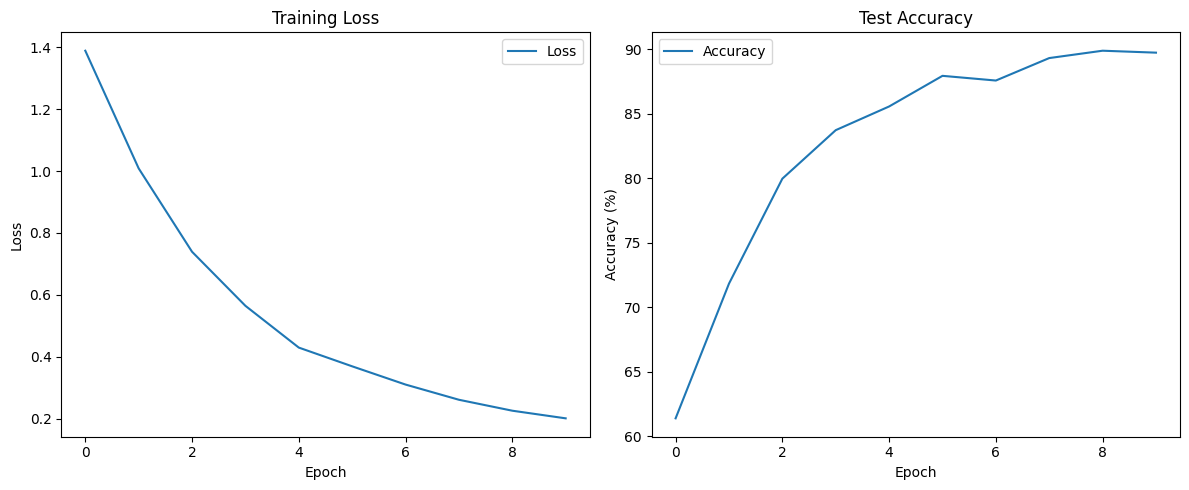


训练完成！
结果图片已经保存为 result.png


In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    loss_history,
    label="Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training Loss")

plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    accuracy_history,
    label="Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("Test Accuracy")

plt.legend()

plt.tight_layout()

plt.savefig(
    "result.png"
)

plt.show()

print("\n训练完成！")
print("结果图片已经保存为 result.png")

In [11]:
from torch.utils.data import DataLoader
from torchvision.transforms import functional as F

In [12]:
# 调整图片亮度
class ChangeBrightness:
    def __init__(self, factor):
        self.factor = factor

    def __call__(self, img):
        return F.adjust_brightness(img, self.factor)

In [13]:
ChangeBrightness(0.6)  # 变暗
ChangeBrightness(1.0)  # 保持原亮度
ChangeBrightness(1.3)  # 变亮

In [14]:
# 低亮度测试集
dark_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    ChangeBrightness(0.6),
    transforms.ToTensor()
])

test_dark = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="test",
    transform=dark_transform,
    download=False
)


# 高亮度测试集
bright_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    ChangeBrightness(1.3),
    transforms.ToTensor()
])

test_bright = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="test",
    transform=bright_transform,
    download=False
)

In [15]:
from torch.utils.data import DataLoader

def evaluate(model, dataset):
    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=0
    )

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


acc_original = evaluate(model, test_dataset)
acc_dark = evaluate(model, test_dark)
acc_bright = evaluate(model, test_bright)

print(f"原始测试集：{acc_original:.2f}%")
print(f"低亮度测试集：{acc_dark:.2f}%")
print(f"高亮度测试集：{acc_bright:.2f}%")

print(f"低亮度下降：{acc_original - acc_dark:.2f} 个百分点")
print(f"高亮度下降：{acc_original - acc_bright:.2f} 个百分点")

原始测试集：89.75%
低亮度测试集：87.59%
高亮度测试集：88.21%
低亮度下降：2.17 个百分点
高亮度下降：1.54 个百分点


In [17]:
from torchvision.transforms import GaussianBlur

blur_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    GaussianBlur(kernel_size=3, sigma=0.8),
    transforms.ToTensor()
])

In [18]:
test_blur = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="test",
    transform=blur_transform,
    download=False
)

print("模糊测试集数量：", len(test_blur))

模糊测试集数量： 12630


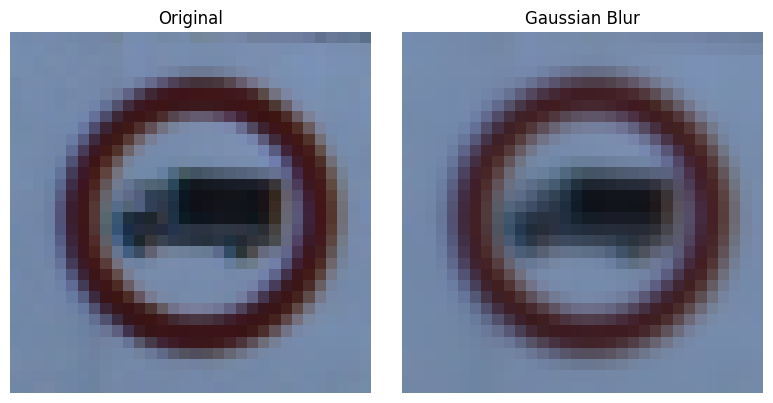

原始标签： 16
模糊后标签： 16


In [19]:
import matplotlib.pyplot as plt

index = 0

img_original, label_original = test_dataset[index]
img_blur, label_blur = test_blur[index]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_original.permute(1, 2, 0))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_blur.permute(1, 2, 0))
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

print("原始标签：", label_original)
print("模糊后标签：", label_blur)

In [20]:
class AddGaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std
        tensor = tensor + noise
        return tensor.clamp(0, 1)

In [21]:
noise_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.03)
])

test_noise = torchvision.datasets.GTSRB(
    root="E:/CV_Data",
    split="test",
    transform=noise_transform,
    download=False
)

print("噪声测试集数量：", len(test_noise))

噪声测试集数量： 12630


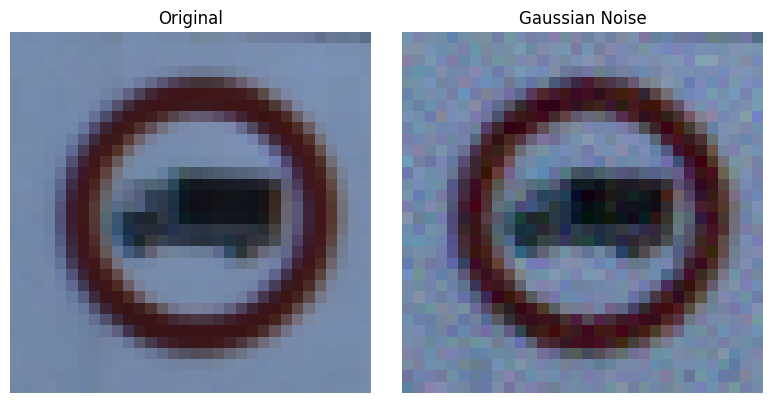

原始标签： 16
噪声后标签： 16


In [22]:
index = 0

img_original, label_original = test_dataset[index]
img_noise, label_noise = test_noise[index]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_original.permute(1, 2, 0))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_noise.permute(1, 2, 0))
plt.title("Gaussian Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

print("原始标签：", label_original)
print("噪声后标签：", label_noise)

In [23]:
acc_original = evaluate(model, test_dataset)
acc_dark = evaluate(model, test_dark)
acc_bright = evaluate(model, test_bright)
acc_blur = evaluate(model, test_blur)
acc_noise = evaluate(model, test_noise)

results = {
    "原始测试集": acc_original,
    "低亮度": acc_dark,
    "高亮度": acc_bright,
    "图像模糊": acc_blur,
    "高斯噪声": acc_noise
}

for name, accuracy in results.items():
    drop = acc_original - accuracy
    print(
        f"{name:10s} 准确率：{accuracy:.2f}%  "
        f"下降：{drop:.2f} 个百分点"
    )

原始测试集      准确率：89.75%  下降：0.00 个百分点
低亮度        准确率：87.59%  下降：2.17 个百分点
高亮度        准确率：88.21%  下降：1.54 个百分点
图像模糊       准确率：87.97%  下降：1.78 个百分点
高斯噪声       准确率：88.04%  下降：1.72 个百分点


## 鲁棒性改进实验

针对上面下降最明显的**亮度变化**与**图像模糊**做一组改进：训练时加数据增强（小角度旋转、平移缩放、亮度对比度抖动），并加上用训练集统计量算的输入标准化；再用 A（基准）/ B（+增强）/ C（+增强+标准化）三组做对照，比较原始测试集准确率与各扰动条件下的下降幅度。

结果：原始测试集准确率 A 91.53% / B 88.63% / C **91.70%**；低亮度的下降幅度 A 3.48 个百分点、C 只有 1.09 个百分点（改善最明显）；但 C 组的模糊与噪声下降幅度反而变大，B 组原始准确率下降、模糊/噪声也更差。

完整的数据表、原因分析和下一步计划见 `思考题.md` 的"附二"。

In [1]:
# 鲁棒性改进实验：环境、数据与工具函数
# 下面重新定义 4 种扰动变换与 evaluate()
# 与前面 cell 中的版本一致

import os
import time

import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.transforms import functional as F

import matplotlib.pyplot as plt

DATA_ROOT = "E:/CV_Data"          # 与你上面 cell 使用的一致
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
BATCH_SIZE = 64
EPOCHS = 10
LR = 1e-3

print("device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)


# ---------------- 扰动变换 ----------------
class ChangeBrightness:
    def __init__(self, factor):
        self.factor = factor

    def __call__(self, img):
        return F.adjust_brightness(img, self.factor)


class AddGaussianNoise:
    def __init__(self, std=0.03):
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std
        return (tensor + noise).clamp(0, 1)


CORRUPTIONS = [None, "dark", "bright", "blur", "noise"]
CORRUPTION_CN = {None: "原始测试集", "dark": "低亮度(×0.6)", "bright": "高亮度(×1.3)",
                 "blur": "图像模糊(σ=0.8)", "noise": "高斯噪声(std=0.03)"}


def build_dataset(split, corruption=None, extra=None):
    """按 扰动 + 可选标准化 组装数据集；extra 传 transforms.Normalize 时启用标准化。"""
    tf = [transforms.Resize((32, 32))]
    if corruption == "dark":
        tf.append(ChangeBrightness(0.6))
    elif corruption == "bright":
        tf.append(ChangeBrightness(1.3))
    elif corruption == "blur":
        tf.append(transforms.GaussianBlur(kernel_size=3, sigma=0.8))
    tf.append(transforms.ToTensor())
    if corruption == "noise":
        tf.append(AddGaussianNoise(std=0.03))
    if extra is not None:
        tf.append(extra)
    return torchvision.datasets.GTSRB(root=DATA_ROOT, split=split,
                                     transform=transforms.Compose(tf), download=False)


def evaluate(model, dataset, batch_size=BATCH_SIZE):
    """与你原来的 evaluate 相同：返回准确率(%)。"""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            pred = model(images).argmax(dim=1)
            correct += (pred == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total


# ---------------- 只用训练集统计量算 mean/std（避免数据泄漏） ----------------
def compute_mean_std(split="train", batch_size=256):
    ds = build_dataset(split)                      # 只做 Resize+ToTensor
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    cnt = 0
    s = torch.zeros(3, dtype=torch.float64)
    s2 = torch.zeros(3, dtype=torch.float64)
    for img, _ in loader:
        img = img.double()
        s += img.sum(dim=[0, 2, 3])
        s2 += (img ** 2).sum(dim=[0, 2, 3])
        cnt += img.shape[0] * img.shape[2] * img.shape[3]
    mean = s / cnt
    std = (s2 / cnt - mean ** 2).sqrt()
    return mean.float(), std.float()


print("正在用训练集统计像素均值/标准差（只用训练集）…")
TRAIN_MEAN, TRAIN_STD = compute_mean_std()
print("训练集 mean =", np.round(TRAIN_MEAN.numpy(), 4))
print("训练集 std  =", np.round(TRAIN_STD.numpy(), 4))

NORMALIZE = transforms.Normalize(TRAIN_MEAN.tolist(), TRAIN_STD.tolist())
print("\n测试集数量：", len(build_dataset("test")), "（与上面 cell[3] 的输出一致）")


device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128
正在用训练集统计像素均值/标准差（只用训练集）…
训练集 mean = [0.3417 0.3126 0.3216]
训练集 std  = [0.2737 0.2607 0.2662]

测试集数量： 12630 （与上面 cell[3] 的输出一致）


In [2]:
# 改进实验：3 组对照训练（唯一变量 = 数据预处理管线）
# A 基准（Resize + ToTensor）
# B 加数据增强
# C 数据增强 + 训练集统计量标准化

class TrafficSignCNN(nn.Module):
    """与你上面 cell[5] 的模型结构完全相同（3 卷积 + 3 池化 + 2 全连接 + Dropout）。"""

    def __init__(self, num_classes=43):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.pool(self.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)


def make_train_transform(arm):
    if arm == "A":
        return transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
    aug = [
        transforms.Resize((32, 32)),
        transforms.RandomRotation(10),                                        # 小角度旋转
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1),
                                scale=(0.9, 1.1)),                            # 平移 + 缩放
        transforms.ColorJitter(brightness=0.3, contrast=0.3),                 # 亮度/对比度抖动
        transforms.ToTensor(),
    ]
    if arm == "C":
        aug.append(NORMALIZE)
    return transforms.Compose(aug)


ARMS = [("A", "基准(原预处理)"), ("B", "改进①:+数据增强"), ("C", "改进②:+增强+标准化")]
# 评估时每组必须用它训练时那套预处理（C 组训练时做了标准化，评估也要做）
EVAL_EXTRA = {"A": None, "B": None, "C": NORMALIZE}
MODELS, HISTORY, TRAIN_TIME = {}, {}, {}


def train_arm(arm, name):
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    model = TrafficSignCNN().to(DEVICE)
    train_ds = build_dataset("train", corruption=None, extra=None)
    train_ds.transform = make_train_transform(arm)          # 按组替换训练预处理
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR)

    loss_hist, acc_hist = [], []
    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        running = 0.0
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running += loss.item()

        avg_loss = running / len(loader)
        acc = evaluate(model, build_dataset("test", extra=EVAL_EXTRA[arm]))  # 每轮在原始测试集上评估（用本组自己的预处理）
        loss_hist.append(avg_loss)
        acc_hist.append(acc)
        print("[%s] Epoch [%2d/%d] Loss %.4f  TestAcc %.2f%%  (%.0fs)"
              % (name, epoch + 1, EPOCHS, avg_loss, acc, time.time() - t0))

    MODELS[arm] = model
    HISTORY[arm] = {"loss": loss_hist, "acc": acc_hist}
    TRAIN_TIME[arm] = time.time() - t0
    torch.save(model.state_dict(), "模型权重/gtsrb_arm_%s.pt" % arm)
    print("[%s] 训练完成，耗时 %.1f 秒，最终原始测试集准确率 %.2f%%\n"
          % (name, TRAIN_TIME[arm], acc_hist[-1]))


for arm, name in ARMS:
    train_arm(arm, name)

print("三组训练全部完成：")
for arm, name in ARMS:
    print("  %-18s 训练耗时 %.0fs  原始测试集准确率 %.2f%%"
          % (name, TRAIN_TIME[arm], HISTORY[arm]["acc"][-1]))


[基准(原预处理)] Epoch [ 1/10] Loss 2.7425  TestAcc 42.01%  (28s)
[基准(原预处理)] Epoch [ 2/10] Loss 1.5502  TestAcc 55.99%  (69s)
[基准(原预处理)] Epoch [ 3/10] Loss 0.9980  TestAcc 75.80%  (171s)
[基准(原预处理)] Epoch [ 4/10] Loss 0.6405  TestAcc 82.72%  (262s)
[基准(原预处理)] Epoch [ 5/10] Loss 0.4577  TestAcc 83.98%  (352s)
[基准(原预处理)] Epoch [ 6/10] Loss 0.3563  TestAcc 88.27%  (443s)
[基准(原预处理)] Epoch [ 7/10] Loss 0.2871  TestAcc 89.47%  (534s)
[基准(原预处理)] Epoch [ 8/10] Loss 0.2372  TestAcc 90.91%  (629s)
[基准(原预处理)] Epoch [ 9/10] Loss 0.1924  TestAcc 90.89%  (740s)
[基准(原预处理)] Epoch [10/10] Loss 0.1784  TestAcc 91.53%  (773s)
[基准(原预处理)] 训练完成，耗时 773.1 秒，最终原始测试集准确率 91.53%

[改进①:+数据增强] Epoch [ 1/10] Loss 3.0253  TestAcc 34.21%  (21s)
[改进①:+数据增强] Epoch [ 2/10] Loss 2.0356  TestAcc 45.53%  (44s)
[改进①:+数据增强] Epoch [ 3/10] Loss 1.6351  TestAcc 55.04%  (175s)
[改进①:+数据增强] Epoch [ 4/10] Loss 1.3596  TestAcc 65.03%  (314s)
[改进①:+数据增强] Epoch [ 5/10] Loss 1.1328  TestAcc 68.73%  (405s)
[改进①:+数据增强] Epoch [ 6/10] Loss 0.9551 

In [3]:
# 三组模型在"原始 + 4 种扰动"测试集上的准确率
import pandas as pd

# 评估用的 EVAL_EXTRA 在上一个 cell 里已定义

rows = {}
for arm, name in ARMS:
    row = {}
    for c in CORRUPTIONS:
        ds = build_dataset("test", corruption=c, extra=EVAL_EXTRA[arm])
        row[CORRUPTION_CN[c]] = evaluate(MODELS[arm], ds)
        print("%-18s | %-18s 准确率 %.2f%%" % (name, CORRUPTION_CN[c], row[CORRUPTION_CN[c]]))
    rows[name] = row
    print("-" * 60)

acc_table = pd.DataFrame(rows).T
acc_table = acc_table[[CORRUPTION_CN[c] for c in CORRUPTIONS]]

# 下降幅度 = 原始测试集准确率 - 该扰动下准确率
drop_table = acc_table.copy()
for col in acc_table.columns[1:]:
    drop_table[col] = acc_table["原始测试集"] - acc_table[col]
drop_table["原始测试集"] = 0.0

print("\n================= 准确率 (%) =================")
print(acc_table.round(2).to_string())
print("\n============= 相对原始测试集的下降幅度 (百分点) =============")
print(drop_table.round(2).to_string())

acc_table.to_csv("q3_robustness_accuracy.csv", encoding="utf-8-sig")
drop_table.to_csv("q3_robustness_drop.csv", encoding="utf-8-sig")
print("\n表格已保存：q3_robustness_accuracy.csv / q3_robustness_drop.csv")

print("\n【改进前后对比（要求 5 的三项）】")
for arm, name in ARMS[1:]:
    print("  改进组 %s 相对基准组 A：" % name)
    print("    a. 原始测试集准确率：%.2f%% -> %.2f%%（%+.2f）"
          % (acc_table.loc["基准(原预处理)", "原始测试集"], acc_table.loc[name, "原始测试集"],
             acc_table.loc[name, "原始测试集"] - acc_table.loc["基准(原预处理)", "原始测试集"]))
    for c in CORRUPTIONS[1:]:
        print("    b. %-16s %.2f%% -> %.2f%%（%+.2f）  c. 下降幅度 %.2f -> %.2f 个百分点"
              % (CORRUPTION_CN[c],
                 acc_table.loc["基准(原预处理)", CORRUPTION_CN[c]], acc_table.loc[name, CORRUPTION_CN[c]],
                 acc_table.loc[name, CORRUPTION_CN[c]] - acc_table.loc["基准(原预处理)", CORRUPTION_CN[c]],
                 drop_table.loc["基准(原预处理)", CORRUPTION_CN[c]], drop_table.loc[name, CORRUPTION_CN[c]]))


基准(原预处理)           | 原始测试集              准确率 91.53%
基准(原预处理)           | 低亮度(×0.6)          准确率 88.05%
基准(原预处理)           | 高亮度(×1.3)          准确率 90.27%
基准(原预处理)           | 图像模糊(σ=0.8)        准确率 89.95%
基准(原预处理)           | 高斯噪声(std=0.03)     准确率 89.75%
------------------------------------------------------------
改进①:+数据增强          | 原始测试集              准确率 88.63%
改进①:+数据增强          | 低亮度(×0.6)          准确率 87.19%
改进①:+数据增强          | 高亮度(×1.3)          准确率 87.62%
改进①:+数据增强          | 图像模糊(σ=0.8)        准确率 85.92%
改进①:+数据增强          | 高斯噪声(std=0.03)     准确率 86.12%
------------------------------------------------------------
改进②:+增强+标准化        | 原始测试集              准确率 91.70%
改进②:+增强+标准化        | 低亮度(×0.6)          准确率 90.61%
改进②:+增强+标准化        | 高亮度(×1.3)          准确率 90.26%
改进②:+增强+标准化        | 图像模糊(σ=0.8)        准确率 88.71%
改进②:+增强+标准化        | 高斯噪声(std=0.03)     准确率 89.34%
------------------------------------------------------------

================= 准确率 (%) =================
       

对比图已保存为 q3_improvement_comparison.png


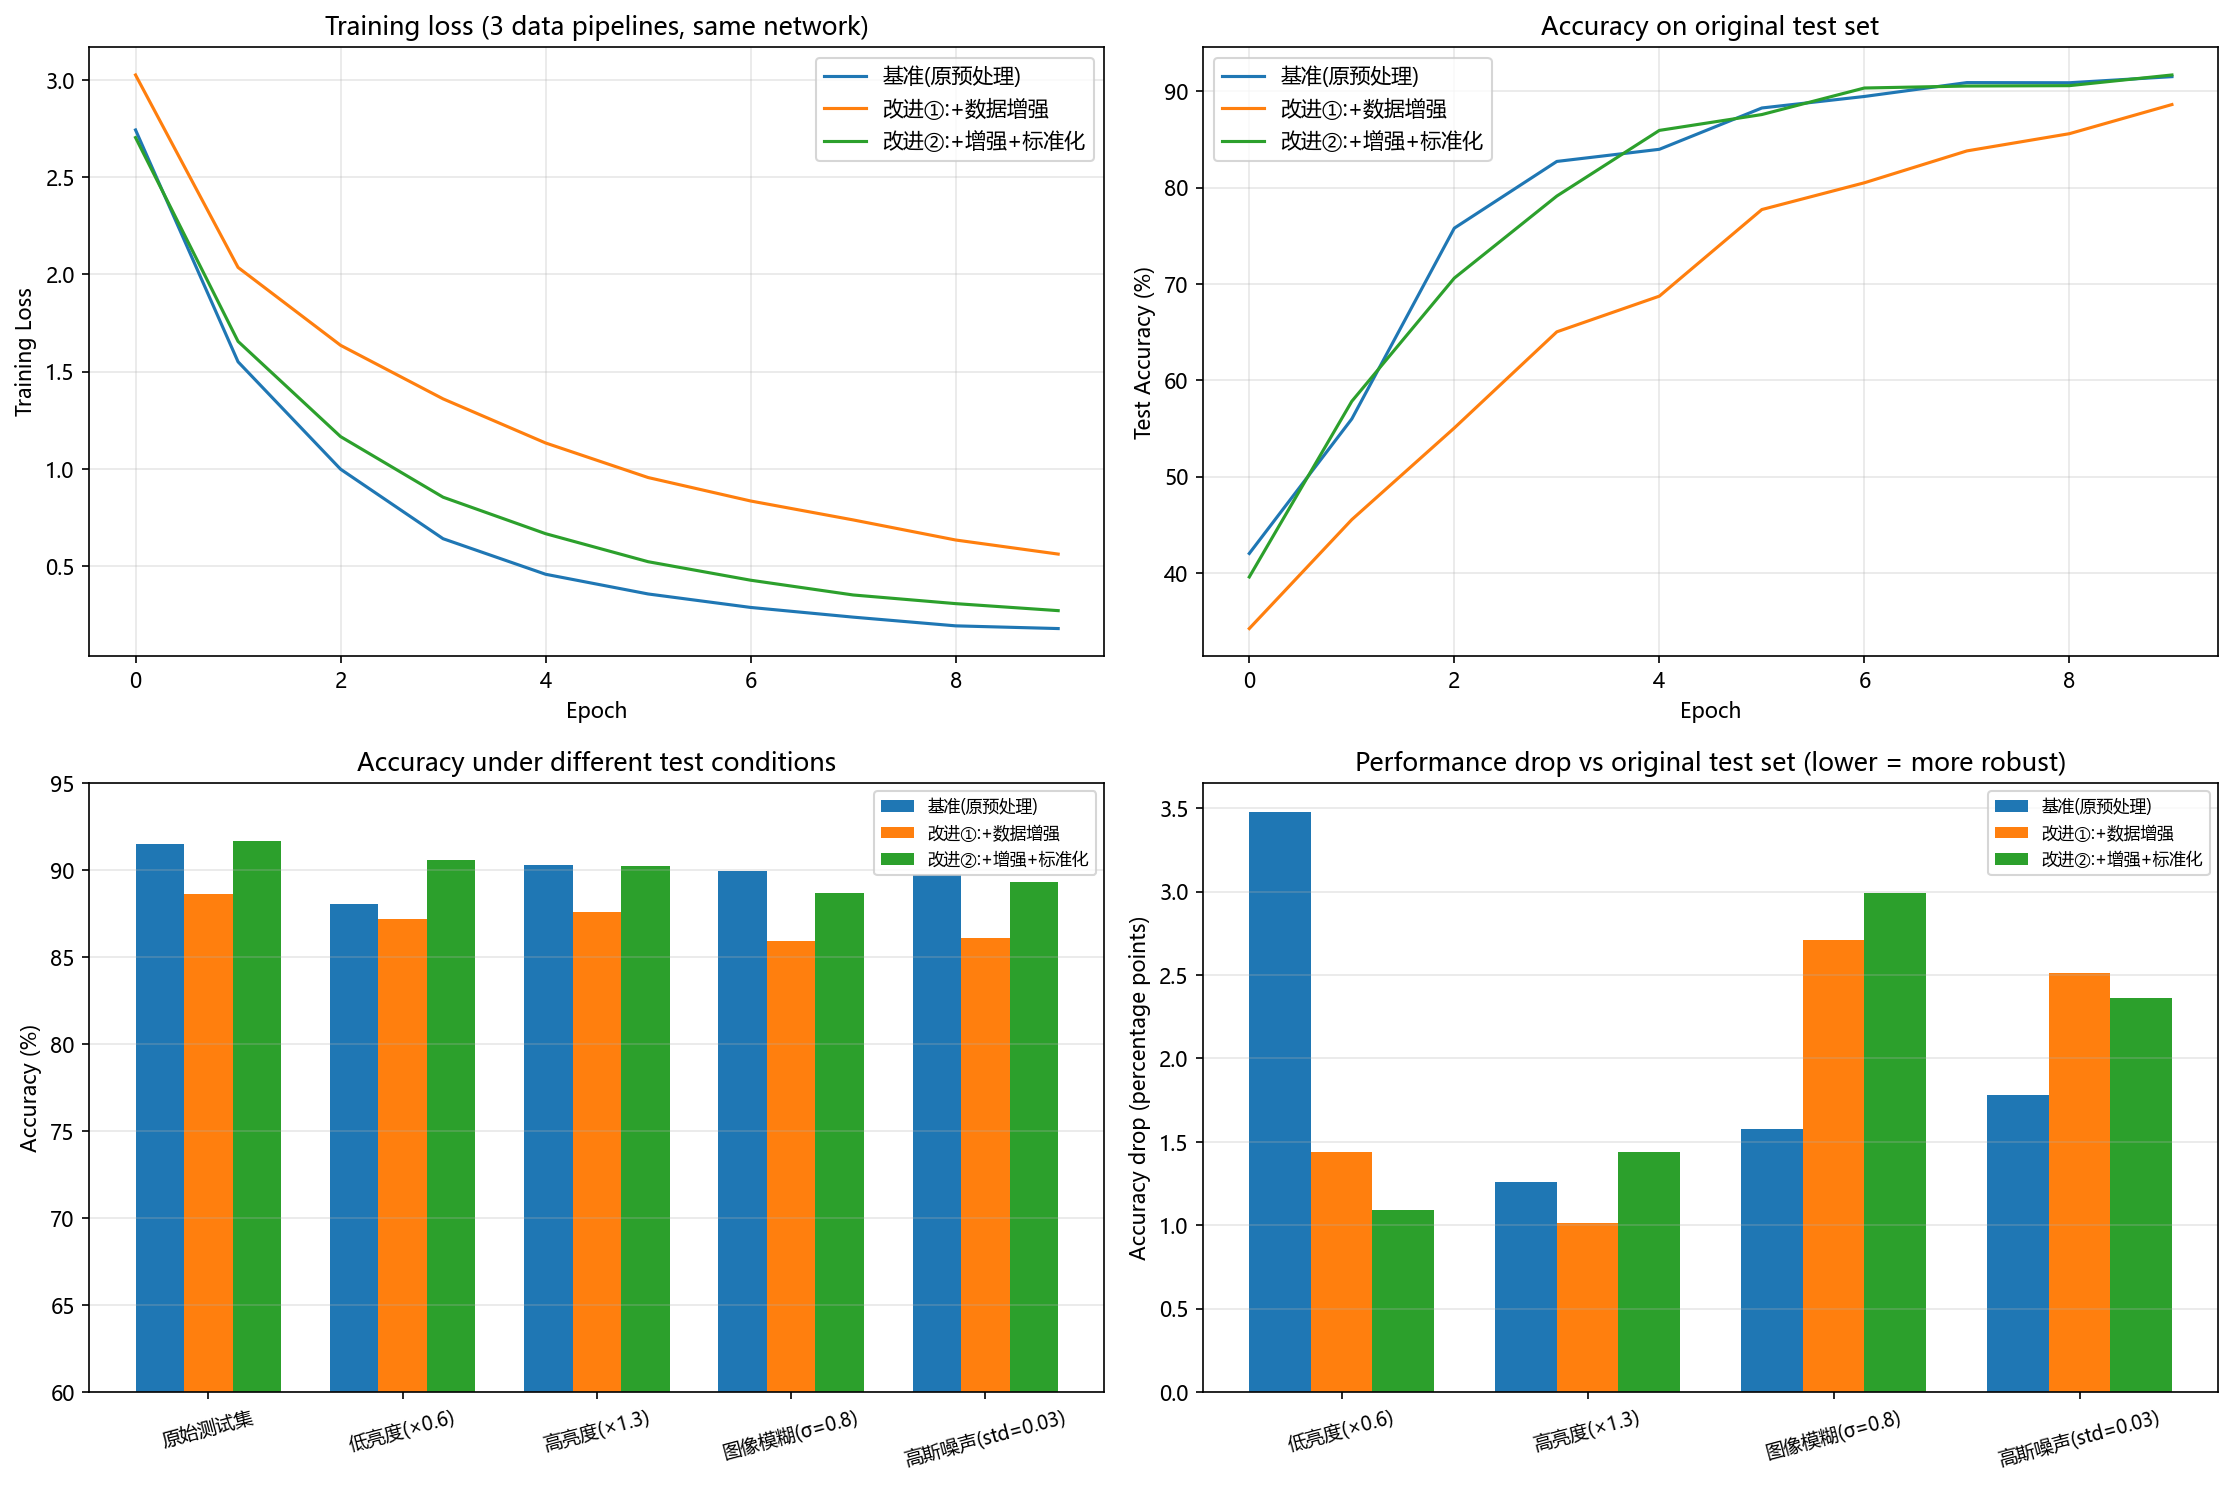

In [4]:
# 改进前后可视化
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) 训练 loss 曲线（三组）
for arm, name in ARMS:
    axes[0, 0].plot(HISTORY[arm]["loss"], label=name)
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Training Loss")
axes[0, 0].set_title("Training loss (3 data pipelines, same network)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# (b) 原始测试集准确率曲线（三组）
for arm, name in ARMS:
    axes[0, 1].plot(HISTORY[arm]["acc"], label=name)
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Test Accuracy (%)")
axes[0, 1].set_title("Accuracy on original test set")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# (c) 各测试条件下的准确率（分组柱状图）
conds = [CORRUPTION_CN[c] for c in CORRUPTIONS]
xpos = np.arange(len(conds))
width = 0.25
for i, (arm, name) in enumerate(ARMS):
    axes[1, 0].bar(xpos + (i - 1) * width, acc_table.loc[name, conds], width=width, label=name)
axes[1, 0].set_xticks(xpos)
axes[1, 0].set_xticklabels(conds, rotation=15, fontsize=9)
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].set_ylim(60, 95)
axes[1, 0].set_title("Accuracy under different test conditions")
axes[1, 0].legend(fontsize=8)
axes[1, 0].grid(alpha=0.3, axis="y")

# (d) 下降幅度（越小越鲁棒）
for i, (arm, name) in enumerate(ARMS):
    axes[1, 1].bar(xpos[1:] + (i - 1) * width, drop_table.loc[name, conds[1:]], width=width, label=name)
axes[1, 1].set_xticks(xpos[1:])
axes[1, 1].set_xticklabels(conds[1:], rotation=15, fontsize=9)
axes[1, 1].set_ylabel("Accuracy drop (percentage points)")
axes[1, 1].set_title("Performance drop vs original test set (lower = more robust)")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig("结果图片/q3_improvement_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("对比图已保存为 q3_improvement_comparison.png")


模型：改进②:+增强+标准化  测试条件：低亮度(×0.6)
该条件下错误样本总数（已扫描部分）：26
错误样本图已保存为 q3_error_samples.png


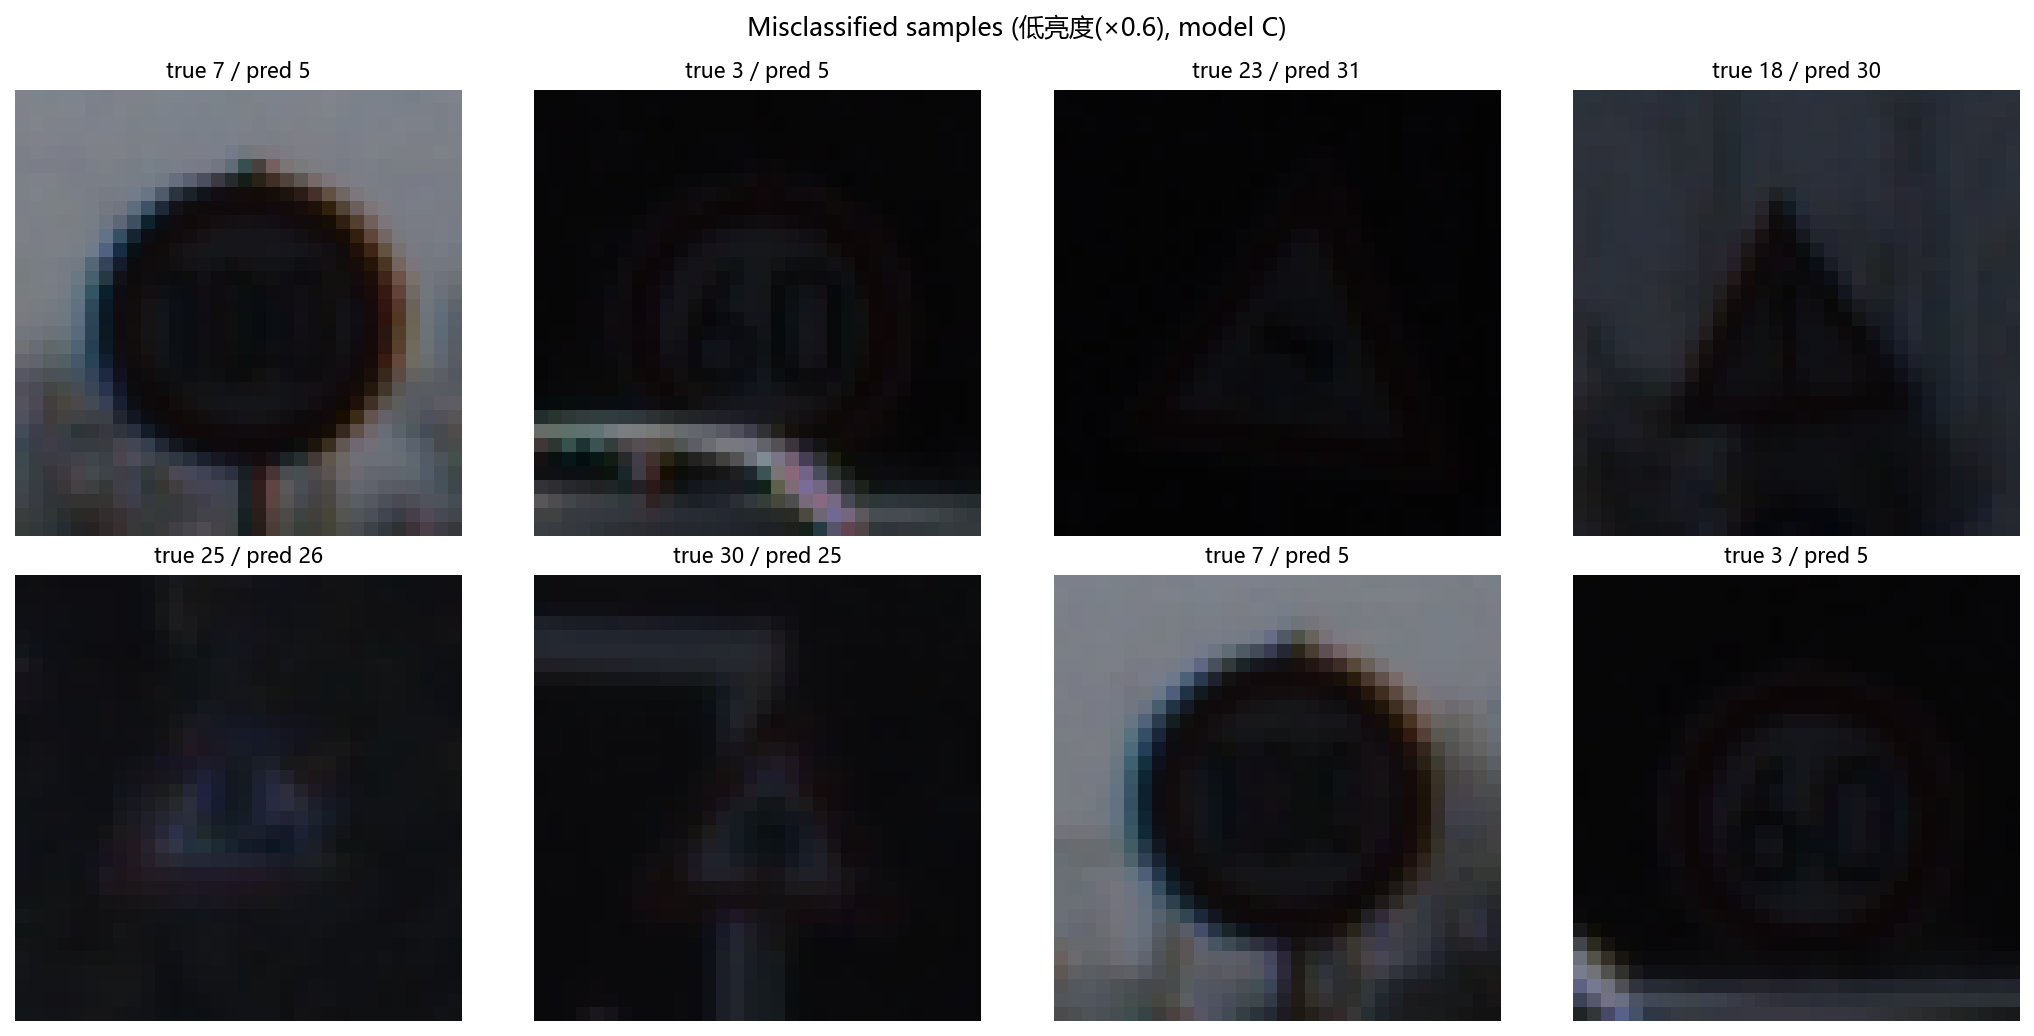

In [5]:
# 可视化仍然容易出错的样本
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
# 观察模型在哪些情况下容易错

# 用最好的那一组模型；这里以"低亮度"扰动为例（若配置不同可改 CORRUPTION_SHOW）
best_arm = max(ARMS, key=lambda a: acc_table.loc[a[1], "原始测试集"])[0]
CORRUPTION_SHOW = "dark"

ds_disp = build_dataset("test", corruption=CORRUPTION_SHOW, extra=None)        # 用于显示
ds_in = build_dataset("test", corruption=CORRUPTION_SHOW,
                      extra=EVAL_EXTRA[best_arm])                              # 用于推理

model_show = MODELS[best_arm]
loader = DataLoader(ds_in, batch_size=256, shuffle=False, num_workers=0)

wrong_idx, wrong_true, wrong_pred = [], [], []
ptr = 0
with torch.no_grad():
    for images, labels in loader:
        pred = model_show(images.to(DEVICE)).argmax(dim=1).cpu()
        for k in range(len(labels)):
            if pred[k] != labels[k]:
                wrong_idx.append(ptr + k)
                wrong_true.append(int(labels[k]))
                wrong_pred.append(int(pred[k]))
        ptr += len(labels)
        if len(wrong_idx) >= 8:
            break

print("模型：%s  测试条件：%s" % (ARMS[[a[0] for a in ARMS].index(best_arm)][1], CORRUPTION_CN[CORRUPTION_SHOW]))
print("该条件下错误样本总数（已扫描部分）：%d" % len(wrong_idx))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx, t, p in zip(axes.ravel(), wrong_idx[:8], wrong_true[:8], wrong_pred[:8]):
    img, _ = ds_disp[idx]
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title("true %d / pred %d" % (t, p), fontsize=10)
    ax.axis("off")
plt.suptitle("Misclassified samples (%s, model %s)" % (CORRUPTION_CN[CORRUPTION_SHOW], best_arm))
plt.tight_layout()
plt.savefig("结果图片/q3_error_samples.png", dpi=150, bbox_inches="tight")
plt.show()
print("错误样本图已保存为 q3_error_samples.png")
